# AQI Forecaster: model training

Trains LightGBM models that forecast the **Indian CPCB AQI** for 25 cities at 1, 3, 6, 12 and 24 hours ahead.

**How to run (Google Colab):** Runtime → Run all. The first run downloads about 2 years of hourly history from Open-Meteo (a few minutes) and caches it in `aqi_history.csv`. At the end, `aqi_model.zip` downloads to your computer.

Put the downloaded zip in `aqi-forecaster/training/` in your project.

In [1]:
!pip -q install lightgbm requests

import os, json, time, zipfile
from datetime import date, timedelta

import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt

YEARS_BACK = 2
END = date.today() - timedelta(days=7)      # the archive weather API lags a few days
START = END - timedelta(days=365 * YEARS_BACK)
HORIZONS = [1, 3, 6, 12, 24]                # hours ahead to forecast
CACHE = "aqi_history.csv"                   # delete this file to force a fresh download
print("History window:", START, "to", END)


History window: 2024-10-25 to 2026-10-25


In [2]:
CITIES = [
    {"name": "Delhi", "lat": 28.6139, "lon": 77.209},
    {"name": "Mumbai", "lat": 19.076, "lon": 72.8777},
    {"name": "Bengaluru", "lat": 12.9716, "lon": 77.5946},
    {"name": "Hyderabad", "lat": 17.385, "lon": 78.4867},
    {"name": "Chennai", "lat": 13.0827, "lon": 80.2707},
    {"name": "Kolkata", "lat": 22.5726, "lon": 88.3639},
    {"name": "Pune", "lat": 18.5204, "lon": 73.8567},
    {"name": "Ahmedabad", "lat": 23.0225, "lon": 72.5714},
    {"name": "Jaipur", "lat": 26.9124, "lon": 75.7873},
    {"name": "Lucknow", "lat": 26.8467, "lon": 80.9462},
    {"name": "Kanpur", "lat": 26.4499, "lon": 80.3319},
    {"name": "Nagpur", "lat": 21.1458, "lon": 79.0882},
    {"name": "Patna", "lat": 25.5941, "lon": 85.1376},
    {"name": "Indore", "lat": 22.7196, "lon": 75.8577},
    {"name": "Bhopal", "lat": 23.2599, "lon": 77.4126},
    {"name": "Chandigarh", "lat": 30.7333, "lon": 76.7794},
    {"name": "Visakhapatnam", "lat": 17.6868, "lon": 83.2185},
    {"name": "Kochi", "lat": 9.9312, "lon": 76.2673},
    {"name": "Thiruvananthapuram", "lat": 8.5241, "lon": 76.9366},
    {"name": "Coimbatore", "lat": 11.0168, "lon": 76.9558},
    {"name": "Surat", "lat": 21.1702, "lon": 72.8311},
    {"name": "Guwahati", "lat": 26.1445, "lon": 91.7362},
    {"name": "Bhubaneswar", "lat": 20.2961, "lon": 85.8245},
    {"name": "Ranchi", "lat": 23.3441, "lon": 85.3096},
    {"name": "Mangaluru", "lat": 12.9141, "lon": 74.856}
]


In [3]:
AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_URL = "https://archive-api.open-meteo.com/v1/archive"
AQ_VARS = ["pm2_5", "pm10", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide", "ozone"]
WX_VARS = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "surface_pressure"]


def get_json(url, params, tries=6):
    for attempt in range(tries):
        r = requests.get(url, params=params, timeout=90)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:
            wait = 30 * (attempt + 1)
            print(f"  rate limited, waiting {wait}s ...")
            time.sleep(wait)
            continue
        r.raise_for_status()
    raise RuntimeError("Open-Meteo kept rate limiting. Wait a few minutes and run this cell again.")


def fetch_city(c):
    common = dict(
        latitude=c["lat"], longitude=c["lon"],
        start_date=START.isoformat(), end_date=END.isoformat(),
        timezone="Asia/Kolkata",
    )
    aq = get_json(AQ_URL, {**common, "hourly": ",".join(AQ_VARS)})["hourly"]
    wx = get_json(WX_URL, {**common, "hourly": ",".join(WX_VARS)})["hourly"]
    df = pd.DataFrame(aq).merge(pd.DataFrame(wx), on="time", how="left")
    df.insert(0, "city", c["name"])
    return df


if os.path.exists(CACHE):
    raw = pd.read_csv(CACHE, parse_dates=["time"])
    print("Loaded cached history:", raw.shape)
else:
    frames = []
    for i, c in enumerate(CITIES, 1):
        print(f"[{i}/{len(CITIES)}] {c['name']}")
        frames.append(fetch_city(c))
        time.sleep(2)
    raw = pd.concat(frames, ignore_index=True)
    raw["time"] = pd.to_datetime(raw["time"])
    raw.to_csv(CACHE, index=False)
    print("Downloaded and cached:", raw.shape)

raw.head()


[1/25] Delhi
[2/25] Mumbai
[3/25] Bengaluru
[4/25] Hyderabad
[5/25] Chennai
[6/25] Kolkata
[7/25] Pune
[8/25] Ahmedabad
[9/25] Jaipur
[10/25] Lucknow
[11/25] Kanpur
[12/25] Nagpur
[13/25] Patna
[14/25] Indore
[15/25] Bhopal
[16/25] Chandigarh
[17/25] Visakhapatnam
[18/25] Kochi
[19/25] Thiruvananthapuram
[20/25] Coimbatore
[21/25] Surat
[22/25] Guwahati
[23/25] Bhubaneswar
[24/25] Ranchi
[25/25] Mangaluru
Downloaded and cached: (438600, 12)


,city,time,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,temperature_2m,relative_humidity_2m,wind_speed_10m,surface_pressure
0,Delhi,2024-10-25 00:00:00,69.8,164.4,662.0,21.1,15.6,72.0,21.7,65,9.9,986.0
1,Delhi,2024-10-25 01:00:00,67.1,148.1,620.0,16.7,14.5,74.0,21.2,68,9.2,985.8
2,Delhi,2024-10-25 02:00:00,66.8,141.6,595.0,14.0,13.9,74.0,20.5,71,8.5,985.4
3,Delhi,2024-10-25 03:00:00,66.4,137.8,582.0,13.3,13.7,70.0,20.0,73,8.1,985.5
4,Delhi,2024-10-25 04:00:00,66.1,135.5,586.0,14.3,13.9,64.0,19.5,76,6.9,985.7


In [4]:
# Same CPCB breakpoints as the Lambda (backend/fetch_aqi/aqi_utils.py), so training and live data match.
PM25_BP = [(0, 30, 0, 50), (30, 60, 51, 100), (60, 90, 101, 200), (90, 120, 201, 300), (120, 250, 301, 400), (250, 380, 401, 500)]
PM10_BP = [(0, 50, 0, 50), (50, 100, 51, 100), (100, 250, 101, 200), (250, 350, 201, 300), (350, 430, 301, 400), (430, 510, 401, 500)]


def sub_index(conc, bps):
    conc = np.asarray(conc, dtype=float)
    out = np.full(conc.shape, np.nan)
    assigned = np.zeros(conc.shape, dtype=bool)
    valid = ~np.isnan(conc)
    for lo, hi, ilo, ihi in bps:
        m = valid & ~assigned & (conc <= hi)
        out[m] = (ihi - ilo) / (hi - lo) * (conc[m] - lo) + ilo
        assigned |= m
    out[valid & ~assigned] = 500
    return np.round(out)


CITY_ID = {c["name"]: i for i, c in enumerate(CITIES)}
LAGS = [1, 2, 3, 6, 12, 24, 48]
POLLUTANTS = ["pm2_5", "pm10", "nitrogen_dioxide", "sulphur_dioxide", "ozone", "carbon_monoxide"]
WEATHER = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "surface_pressure"]

FEATURES = (
    ["aqi_now"] + [f"aqi_lag{L}" for L in LAGS] + ["aqi_roll6", "aqi_roll24"]
    + POLLUTANTS + ["pm2_5_lag24"] + WEATHER
    + ["hour", "dow", "month", "hour_sin", "hour_cos", "city_id"]
)


def build_features(df):
    parts = []
    for city, g in df.groupby("city"):
        g = g.sort_values("time").set_index("time")
        g = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq="h"))
        g.index.name = "time"
        g["city"] = city

        pm25_24 = g["pm2_5"].rolling(24, min_periods=16).mean()
        pm10_24 = g["pm10"].rolling(24, min_periods=16).mean()
        g["aqi"] = np.fmax(sub_index(pm25_24, PM25_BP), sub_index(pm10_24, PM10_BP))

        g["aqi_now"] = g["aqi"]
        for L in LAGS:
            g[f"aqi_lag{L}"] = g["aqi"].shift(L)
        g["aqi_roll6"] = g["aqi"].rolling(6, min_periods=4).mean()
        g["aqi_roll24"] = g["aqi"].rolling(24, min_periods=16).mean()
        g["pm2_5_lag24"] = g["pm2_5"].shift(24)

        idx = g.index
        g["hour"] = idx.hour
        g["dow"] = idx.dayofweek
        g["month"] = idx.month
        g["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
        g["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
        g["city_id"] = CITY_ID[city]

        for h in HORIZONS:
            g[f"y{h}"] = g["aqi"].shift(-h)
        parts.append(g.reset_index())
    return pd.concat(parts, ignore_index=True)


data = build_features(raw)
print(data.shape)
data[["city", "time", "aqi_now", "y24"]].dropna().tail()


(438600, 35)


,city,time,aqi_now,y24
438571,Visakhapatnam,2026-10-24 19:00:00,176.0,170.0
438572,Visakhapatnam,2026-10-24 20:00:00,178.0,168.0
438573,Visakhapatnam,2026-10-24 21:00:00,179.0,166.0
438574,Visakhapatnam,2026-10-24 22:00:00,181.0,162.0
438575,Visakhapatnam,2026-10-24 23:00:00,184.0,158.0


In [5]:
t_max = data["time"].max()
test_start = t_max - pd.Timedelta(days=30)
val_start = test_start - pd.Timedelta(days=30)
print("train < ", val_start.date(), "| val < ", test_start.date(), "| test up to", t_max.date())

PARAMS = dict(
    n_estimators=1500, learning_rate=0.05, num_leaves=63, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1,
)


def to_category(a):
    return np.digitize(a, [50, 100, 200, 300, 400], right=True)


rows, best_iters, models, test_store = [], {}, {}, {}
for h in HORIZONS:
    target = f"y{h}"
    d = data.dropna(subset=[target, "aqi_now"])
    train = d[d["time"] < val_start]
    val = d[(d["time"] >= val_start) & (d["time"] < test_start)]
    test = d[d["time"] >= test_start]

    m = lgb.LGBMRegressor(**PARAMS)
    m.fit(
        train[FEATURES], train[target],
        eval_set=[(val[FEATURES], val[target])], eval_metric="l1",
        categorical_feature=["city_id"],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    pred = m.predict(test[FEATURES])
    base = test["aqi_now"].values          # baseline: "AQI stays the same"
    y = test[target].values

    def metrics(p):
        err = p - y
        return (
            np.abs(err).mean(),
            np.sqrt((err ** 2).mean()),
            1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            (to_category(p) == to_category(y)).mean(),
        )

    mae, rmse, r2, acc = metrics(pred)
    b_mae, b_rmse, b_r2, b_acc = metrics(base)
    rows.append(dict(horizon_h=h, MAE=mae, base_MAE=b_mae, RMSE=rmse, base_RMSE=b_rmse,
                     R2=r2, base_R2=b_r2, cat_acc=acc, base_cat_acc=b_acc))
    best_iters[h] = max(int(m.best_iteration_ or 100), 50)
    models[h] = m
    test_store[h] = test[["time", "city", target, "aqi_now"]].assign(pred=pred).rename(columns={target: "actual"})
    print(f"h={h:>2}h  model MAE {mae:6.2f} vs persistence {b_mae:6.2f}  | category accuracy {acc:.1%} vs {b_acc:.1%}")

results = pd.DataFrame(rows).round(3)
results


train <  2026-08-26 | val <  2026-09-25 | test up to 2026-10-25
h= 1h  model MAE   0.59 vs persistence   1.07  | category accuracy 99.0% vs 98.4%
h= 3h  model MAE   1.61 vs persistence   3.14  | category accuracy 97.5% vs 95.2%
h= 6h  model MAE   3.52 vs persistence   6.02  | category accuracy 94.7% vs 90.8%
h=12h  model MAE   7.61 vs persistence  11.03  | category accuracy 88.1% vs 83.0%
h=24h  model MAE  15.20 vs persistence  18.26  | category accuracy 77.6% vs 72.8%


,horizon_h,MAE,base_MAE,RMSE,base_RMSE,R2,base_R2,cat_acc,base_cat_acc
0,1,0.594,1.072,0.941,1.837,1.000,0.999,0.990,0.984
1,3,1.608,3.136,2.760,5.228,0.997,0.990,0.975,0.952
2,6,3.517,6.015,5.899,9.900,0.987,0.963,0.947,0.908
3,12,7.614,11.027,12.297,17.723,0.943,0.882,0.881,0.830
4,24,15.196,18.265,23.730,28.375,0.788,0.697,0.776,0.728


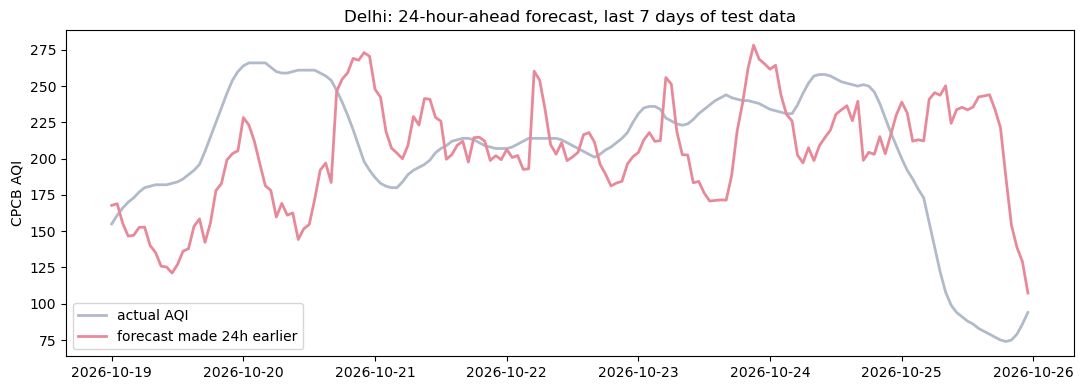

Top features for the 24h model:
city_id             1446
aqi_lag48           1251
pm2_5               1109
aqi_lag24            959
month                904
pm10                 903
surface_pressure     876
pm2_5_lag24          857
aqi_now              788
dow                  698
dtype: int32


In [7]:
CITY_TO_PLOT = "Delhi"
H = 24

sub = test_store[H].query("city == @CITY_TO_PLOT").sort_values("time").tail(24 * 7)
x = sub["time"] + pd.Timedelta(hours=H)     # a forecast made at time t is for time t + H

plt.figure(figsize=(11, 4))
plt.plot(x, sub["actual"], label="actual AQI", color="#B1BACB", linewidth=2)
plt.plot(x, sub["pred"], label=f"forecast made {H}h earlier", color="#E8899A", linewidth=2)
plt.title(f"{CITY_TO_PLOT}: {H}-hour-ahead forecast, last 7 days of test data")
plt.ylabel("CPCB AQI")
plt.legend()
plt.tight_layout()
plt.show()

imp = pd.Series(models[H].feature_importances_, index=FEATURES).sort_values(ascending=False)
print("Top features for the 24h model:")
print(imp.head(10))


In [8]:
# Refit each model on ALL data (using the best number of trees found above) and save for deployment.
os.makedirs("model", exist_ok=True)

for h in HORIZONS:
    d = data.dropna(subset=[f"y{h}", "aqi_now"])
    final = lgb.LGBMRegressor(**{**PARAMS, "n_estimators": best_iters[h]})
    final.fit(d[FEATURES], d[f"y{h}"], categorical_feature=["city_id"])
    final.booster_.save_model(f"model/aqi_lgbm_h{h}.txt")

meta = dict(
    features=FEATURES,
    horizons=HORIZONS,
    lags=LAGS,
    cities=[c["name"] for c in CITIES],
    city_id=CITY_ID,
    trained_through=str(t_max),
    test_results=results.to_dict(orient="records"),
)
with open("model/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

with zipfile.ZipFile("aqi_model.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in os.listdir("model"):
        z.write(os.path.join("model", name), name)
print("Saved:", os.listdir("model"))

try:
    from google.colab import files
    files.download("aqi_model.zip")
except ImportError:
    print("Not running in Colab; find aqi_model.zip in the working folder.")


Saved: ['aqi_lgbm_h1.txt', 'aqi_lgbm_h12.txt', 'aqi_lgbm_h24.txt', 'aqi_lgbm_h3.txt', 'aqi_lgbm_h6.txt', 'meta.json']
Not running in Colab; find aqi_model.zip in the working folder.
